# ICT-4202 | Artificial Intelligence and Machine Learning Laboratory
## Final Laboratory Examination — Set 07
**Islamic University, Kushtia, Bangladesh**  
Department of Information and Communication Technology

> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Family FOL knowledge representation | 25 |
| Q2 | Greedy best-first heuristic sensitivity | 30 |
| Q3 | K-means with standardization | 35 |
| Q4 | Viva: relations, heuristics, scaling, silhouette | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Source:** `AI_MLQuestionList.pdf` (uploaded exam sheet), pages 4; background concepts from the supplied ICT-4202 laboratory manual. The source questions govern specifications; where a question leaves a parameter open, our choice is explicitly labeled.

**Quick access - one file per numbered question:** [Q1 / A](Set_07_A.py) | [Q2 / B](Set_07_B.py) | [Q3 / C](Set_07_C.py) | [Q4 / D: Viva practice](Set_07_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. FOL and Knowledge Representation (25 marks)
**Question specification**  
`Parent(Rahman,Hasan)`, `Parent(Rahman,Nabila)`, `Parent(Hasan,Rafi)`, `Parent(Nabila,Tania)`, `Parent(Rafi,Samia)`. Implement `children_of(x)`, `grandchildren_of(x)`, `grandparent(x,z)` and `siblings(x,y)` avoiding duplicates/self-siblings.

### Theory and mathematical background
First-order logic models named **objects** and **relations**. For instance, $Parent(Ali,Babu)$ asserts a binary relation; `Ali` and `Babu` are constants, whereas $x,y,z$ are variables.

A grandparent inference rule is
$$\forall x\,\forall y\,\forall z:\quad Parent(x,y)\land Parent(y,z)\Rightarrow Grandparent(x,z).$$
A sibling relation uses a shared parent:
$$Sibling(x,y)\Leftarrow\exists p\, [Parent(p,x)\land Parent(p,y)\land x\ne y].$$
The implementation below demonstrates **specific relation inference over Python tuples**, not a general-purpose first-order theorem prover.

In [1]:
from itertools import combinations

def children_of(person, parents):
    return sorted({child for parent, child in parents if parent == person})

def grandparent_relations(parents):
    return sorted({(x, z) for x, y in parents for middle, z in parents if y == middle})

def siblings_relations(parents):
    result = set()
    for p in {person for person, child in parents}:
        children = children_of(p, parents)
        for x, y in combinations(children, 2):
            result.add((x, y))  # Canonical unordered pair: no duplicates/self-pairs.
    return sorted(result)

def print_relations(parents):
    people = sorted({x for pair in parents for x in pair})
    print('Parent facts:', sorted(parents))
    print('Children queries:')
    for name in people:
        kids = children_of(name, parents)
        if kids: print(f'  children_of({name}) = {kids}')
    print('Grandparent relations:', grandparent_relations(parents))
    print('Sibling relations (unordered):', siblings_relations(parents))

parents={('Rahman','Hasan'),('Rahman','Nabila'),('Hasan','Rafi'),
         ('Nabila','Tania'),('Rafi','Samia')}
def grandchildren_of(person):
    return sorted({z for x,z in grandparent_relations(parents) if x==person})
def grandparent(x,z):
    return (x,z) in grandparent_relations(parents)
def siblings(x,y):
    return x!=y and tuple(sorted((x,y))) in siblings_relations(parents)
print_relations(parents)
for name in ['Rahman','Hasan','Nabila','Rafi']:
    print(f'grandchildren_of({name}): {grandchildren_of(name)}')
print('grandparent(Rahman,Rafi)=',grandparent('Rahman','Rafi'))
print('siblings(Hasan,Nabila)=',siblings('Hasan','Nabila'))
print('siblings(Hasan,Hasan)=',siblings('Hasan','Hasan'))
assert not siblings('Hasan','Hasan')


Parent facts: [('Hasan', 'Rafi'), ('Nabila', 'Tania'), ('Rafi', 'Samia'), ('Rahman', 'Hasan'), ('Rahman', 'Nabila')]
Children queries:
  children_of(Hasan) = ['Rafi']
  children_of(Nabila) = ['Tania']
  children_of(Rafi) = ['Samia']
  children_of(Rahman) = ['Hasan', 'Nabila']
Grandparent relations: [('Hasan', 'Samia'), ('Rahman', 'Rafi'), ('Rahman', 'Tania')]
Sibling relations (unordered): [('Hasan', 'Nabila')]
grandchildren_of(Rahman): ['Rafi', 'Tania']
grandchildren_of(Hasan): ['Samia']
grandchildren_of(Nabila): []
grandchildren_of(Rafi): []
grandparent(Rahman,Rafi)= True
siblings(Hasan,Nabila)= True
siblings(Hasan,Hasan)= False


### Result interpretation and discussion
The intermediate variable of the grandparent rule corresponds to the shared person in two Parent tuples. Canonical pairs make sibling relations unordered and unique; a person is never considered their own sibling.

---
## Q2. Greedy Best-First Search (30 marks)
**Question specification**  
`S→{A,B,C}, A→{D}, B→{E}, C→{F}, D→{G}, E→{G}, F→{G}`. Given `h(S,A,B,C,D,E,F,G)=(7,4,5,3,2,2,1,0)`, run Greedy; modify heuristics to make it explore a less-useful branch first. Print both traces and explain.

### Theory and mathematical background
A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from collections import deque

import heapq

from itertools import count

def greedy_unweighted(graph, h, start, goal):
    tie = count()
    heap = [(h[start], next(tie), start, [start])]
    seen, expanded = set(), []
    while heap:
        _, _, node, path = heapq.heappop(heap)
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                heapq.heappush(heap, (h[nxt], next(tie), nxt, path + [nxt]))
    return None, expanded

graph={'S':['A','B','C'],'A':['D'],'B':['E'],'C':['F'],
       'D':['G'],'E':['G'],'F':['G'],'G':[]}
original_h={'S':7,'A':4,'B':5,'C':3,'D':2,'E':2,'F':1,'G':0}
misleading_h=dict(original_h)
misleading_h['A']=0   # Prefer A immediately despite the longer-looking D estimate.
misleading_h['D']=20  # Discourage finishing branch A-D, causing wasted expansion of A.
for label,h in [('Original',original_h),('Modified/misleading',misleading_h)]:
    path,expanded=greedy_unweighted(graph,h,'S','G')
    print(label,'heuristics:',h)
    print('  expanded:',expanded,'| count:',len(expanded),'| path:',path)


Original heuristics: {'S': 7, 'A': 4, 'B': 5, 'C': 3, 'D': 2, 'E': 2, 'F': 1, 'G': 0}
  expanded: ['S', 'C', 'F', 'G'] | count: 4 | path: ['S', 'C', 'F', 'G']
Modified/misleading heuristics: {'S': 7, 'A': 0, 'B': 5, 'C': 3, 'D': 20, 'E': 2, 'F': 1, 'G': 0}
  expanded: ['S', 'A', 'C', 'F', 'G'] | count: 5 | path: ['S', 'C', 'F', 'G']


### Result interpretation and discussion
With the modified heuristics, Greedy visits an initially attractive `A` before choosing another frontier branch, wasting an expansion. **All three S-to-G branches in this particular graph have three edges**, so this example demonstrates misleading search *order/efficiency*, not a longer returned edge-count path. This distinction follows the supplied graph exactly.

---
## Q3. K-means and Feature Scaling (35 marks)
**Question specification**  
Using all 4 numeric Iris features, run K-means $k=3$ without scaling, record centers/inertia/silhouette; standardize **all** features, rerun, compare and visualize using any two features. Explain why centers and inertia across units are not directly comparable.

### Theory and mathematical background
**K-means** is an unsupervised clustering method that alternates assigning samples to the nearest centroid and updating centroids. For $K$ clusters, it seeks to minimize
$$J=\sum_{i=1}^{n}\left\|\mathbf x_i-\boldsymbol\mu_{z_i}\right\|_2^2.$$
`inertia_` is the final within-cluster sum of squares. The silhouette of a sample is
$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},$$
where $a(i)$ is average within-cluster distance and $b(i)$ is its smallest mean distance to another cluster. Larger silhouette generally indicates better-separated clusters. **Cluster IDs are arbitrary** and are not species class labels.

Feature scaling changes the distance geometry and inertia's units; compare inertia only for models using comparable feature representations.


Original cm: inertia=78.8514, silhouette=0.5528
Centroids in model coordinate system:
 [[5.902 2.748 4.394 1.434]
 [5.006 3.428 1.462 0.246]
 [6.85  3.074 5.742 2.071]]

Standardized z-scores: inertia=139.8205, silhouette=0.4599
Centroids in model coordinate system:
 [[-0.05  -0.883  0.348  0.282]
 [-1.015  0.853 -1.305 -1.255]
 [ 1.136  0.088  0.996  1.018]]

Scaled centroids mapped BACK to cm (for interpretation; order is arbitrary):
 [[5.802 2.674 4.37  1.413]
 [5.006 3.428 1.462 0.246]
 [6.781 3.096 5.511 1.972]]


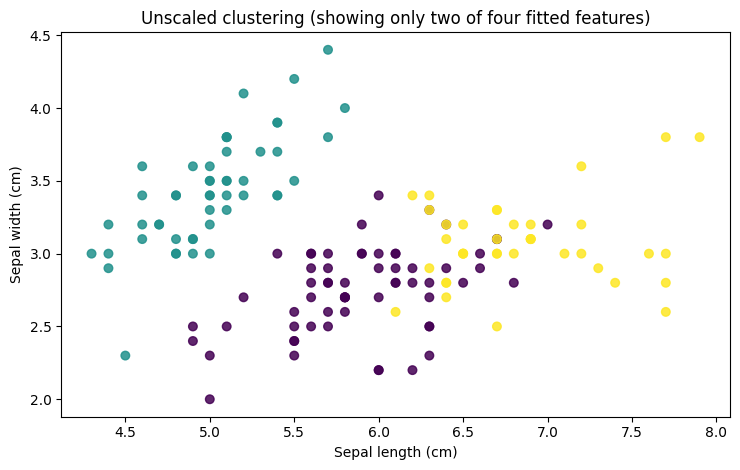

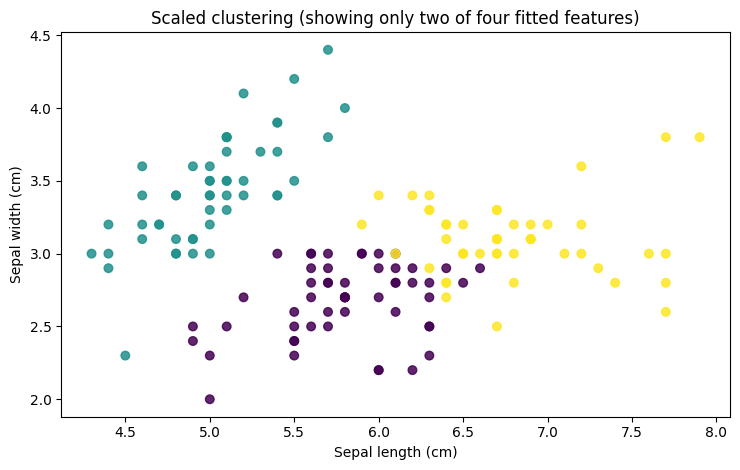

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
iris = load_iris()

X=iris.data.copy()
raw=KMeans(n_clusters=3,random_state=42,n_init=10).fit(X)
scaler=StandardScaler().fit(X)
X_scaled=scaler.transform(X)
scaled=KMeans(n_clusters=3,random_state=42,n_init=10).fit(X_scaled)
for name,features,fit in [('Original cm',X,raw),('Standardized z-scores',X_scaled,scaled)]:
    print(f'\n{name}: inertia={fit.inertia_:.4f}, silhouette={silhouette_score(features,fit.labels_):.4f}')
    print('Centroids in model coordinate system:\n',fit.cluster_centers_.round(3))
print('\nScaled centroids mapped BACK to cm (for interpretation; order is arbitrary):\n',
      scaler.inverse_transform(scaled.cluster_centers_).round(3))
for title,labels in [('Unscaled clustering',raw.labels_),('Scaled clustering',scaled.labels_)]:
    plt.figure(figsize=(7.5,4.8))
    plt.scatter(X[:,0],X[:,1],c=labels,cmap='viridis',alpha=.85,s=38)
    plt.xlabel('Sepal length (cm)');plt.ylabel('Sepal width (cm)')
    plt.title(title+' (showing only two of four fitted features)');plt.tight_layout();plt.show()


### Result interpretation and discussion
Raw K-means measures squared distances in cm (original feature units); standardized K-means uses z-scores and changes relative feature contributions. The centroid coordinates and inertia therefore live in **different feature spaces**. A plot of two features does **not** mean the model was trained on just two; both fits used all four.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| What is FOL? | Logic with objects, predicates, variables, and quantifiers. |
| What makes two people siblings? | They share a parent and are distinct people. |
| What is Greedy best-first? | Heuristic-priority search using h only. |
| Can misleading heuristics add expansions? | Yes; they may prioritize a branch that does not advance toward the goal. |
| Is K-means supervised? | No; it does not use class labels during fit. |
| What does scaling affect? | The distances, and thus centroids, cluster assignments, and inertia. |
| What is silhouette? | A dimensionless separation/cohesion measure within one feature space. |

| What is a binary relation? | A predicate connecting two objects, such as Parent(Rahman, Hasan). |
| Why not compare K-means inertia before and after scaling directly? | Scaling changes the numerical distances and therefore changes the units and magnitude of inertia. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.